## Sales Forecasting Model

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
df = pd.read_csv("sales_forecasting_dataset.csv")
print(df)

           Date        Product          Category   Region  Quantity_Sold  \
0    2024-01-01      Bookshelf         Furniture  Central             22   
1    2024-01-01       Yoga Mat  Sports & Fitness    South             10   
2    2024-01-01   Office Chair         Furniture     West              4   
3    2024-01-02  Bed Sheet Set     Home & Living     West              2   
4    2024-01-02  Bed Sheet Set     Home & Living     West             18   
..          ...            ...               ...      ...            ...   
995  2025-12-29      Bookshelf         Furniture  Central             23   
996  2025-12-29   Notebook Set        Stationery     East             34   
997  2025-12-30       Pen Pack        Stationery     West             12   
998  2025-12-30       Backpack           Apparel  Central             17   
999  2025-12-30   Office Chair         Furniture    North              5   

     Unit_Price  Discount  Total_Sales  
0       4533.15       5.0     94742.83  
1    

In [53]:
print(df.shape)
print(df.isnull().sum())
print(df.describe())

(1000, 8)
Date             0
Product          0
Category         0
Region           0
Quantity_Sold    0
Unit_Price       0
Discount         0
Total_Sales      0
dtype: int64
       Quantity_Sold   Unit_Price     Discount    Total_Sales
count    1000.000000  1000.000000  1000.000000    1000.000000
mean       13.640000  2338.139760     6.735000   28623.556810
std         8.561641  2393.427689     6.816248   37093.635786
min         1.000000   135.910000     0.000000     135.120000
25%         7.000000   681.097500     0.000000    4911.447500
50%        13.000000  1426.135000     5.000000   14587.610000
75%        20.000000  3401.110000    10.000000   35882.510000
max        42.000000  9820.280000    25.000000  271968.670000


In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           1000 non-null   str    
 1   Product        1000 non-null   str    
 2   Category       1000 non-null   str    
 3   Region         1000 non-null   str    
 4   Quantity_Sold  1000 non-null   int64  
 5   Unit_Price     1000 non-null   float64
 6   Discount       1000 non-null   float64
 7   Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), str(4)
memory usage: 98.6 KB


### Extracting Features

## Performing EDA

### Univariate Analysis

In [55]:
df['Category'].value_counts()

Category
Electronics         246
Home & Living       168
Apparel             163
Furniture           161
Sports & Fitness    133
Stationery          129
Name: count, dtype: int64

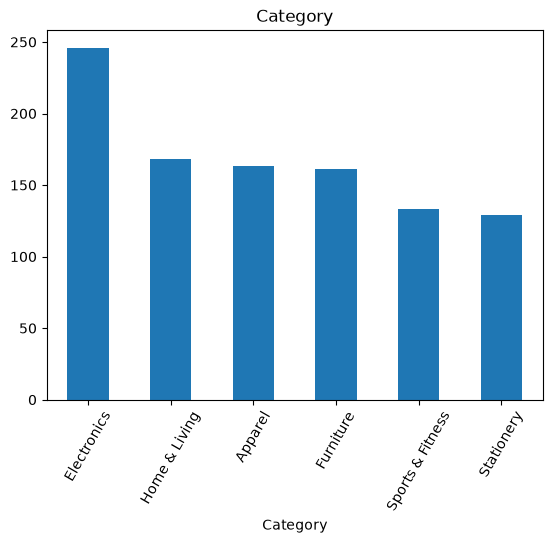

In [56]:
plt.Figure(figsize=(10,8))
df['Category'].value_counts().plot(kind='bar')
plt.xticks(rotation = 60)
plt.title('Category')
plt.show()

In [57]:
df['Product'].value_counts()

Product
Laptop Stand         71
Dumbbell Set         70
Pen Pack             68
Study Table          64
Table Lamp           64
Yoga Mat             63
USB-C Cable          63
Running Shoes        62
Notebook Set         61
Curtains             58
Bluetooth Speaker    57
T-Shirt              55
Wireless Mouse       55
Office Chair         53
Bed Sheet Set        46
Backpack             46
Bookshelf            44
Name: count, dtype: int64

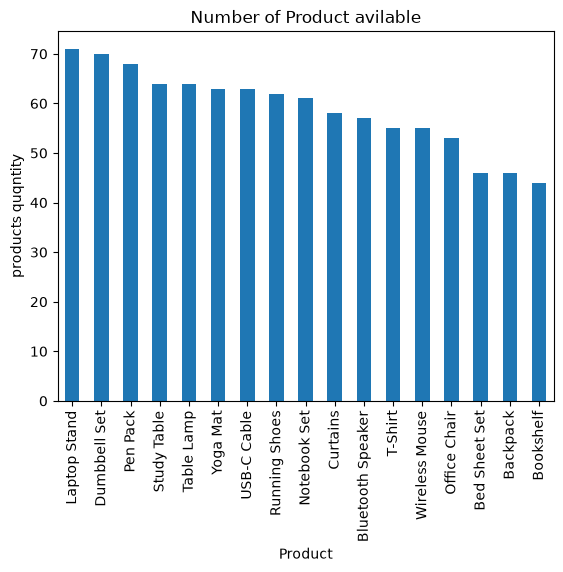

In [58]:
df['Product'].value_counts().plot(kind='bar')
plt.title('Number of Product avilable')
plt.xticks(rotation = 90)
plt.ylabel('products quqntity')
plt.show()


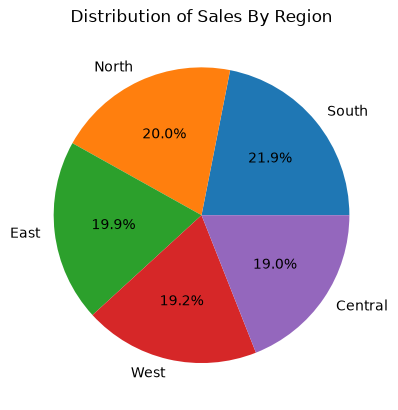

In [59]:
region = df['Region'].value_counts()
plt.pie(df['Region'].value_counts(),labels=region.index,autopct='%1.1f%%')
plt.title('Distribution of Sales By Region')
plt.show()


Text(0.5, 1.0, 'Distribution of Quantity sold')

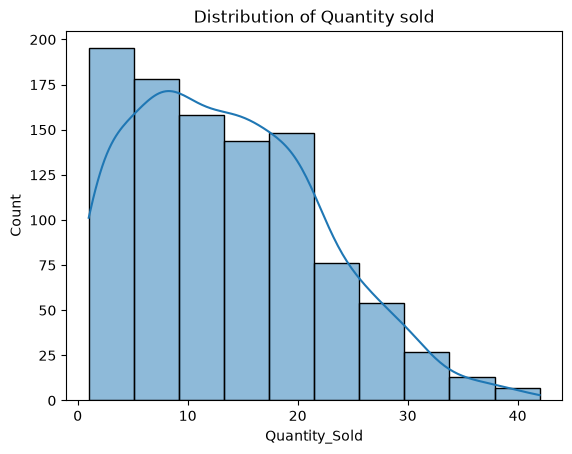

In [60]:
sns.histplot(df['Quantity_Sold'],bins= 10, kde= True)
plt.title('Distribution of Quantity sold')

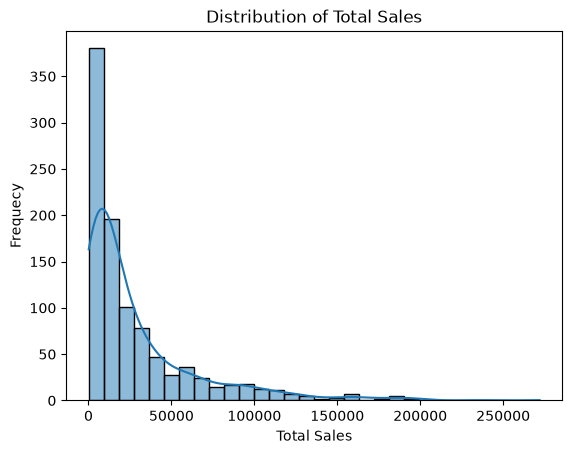

In [61]:
sns.histplot(df['Total_Sales'], bins= 30, kde= True)
plt.title('Distribution of Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Frequecy')
plt.show()

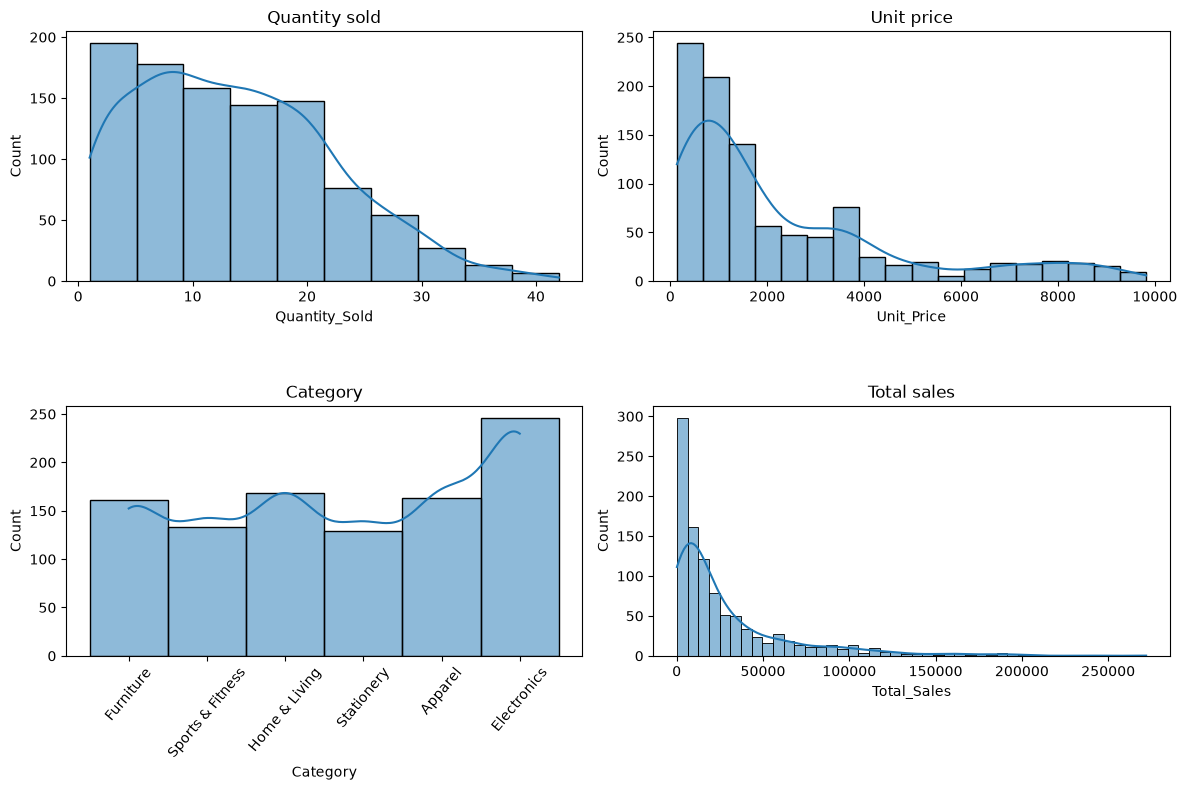

In [62]:
plt.figure(figsize=(12, 8))
plt.subplot(2,2,1)
sns.histplot(df['Quantity_Sold'],kde= True, bins=10)
plt.title('Quantity sold')

plt.subplot(2,2,2)
sns.histplot(df['Unit_Price'],kde= True)
plt.title('Unit price')

plt.subplot(2,2,3)
sns.histplot(df['Category'],kde= True)
plt.xticks(rotation = 50)
plt.title('Category')

plt.subplot(2,2,4)
sns.histplot(df['Total_Sales'],kde= True)
plt.title('Total sales')

plt.tight_layout()
plt.subplots_adjust(hspace=0.5)

# Bivariate Analysis

Text(0.5, 1.0, 'Quantity sold Vs Total Sales')

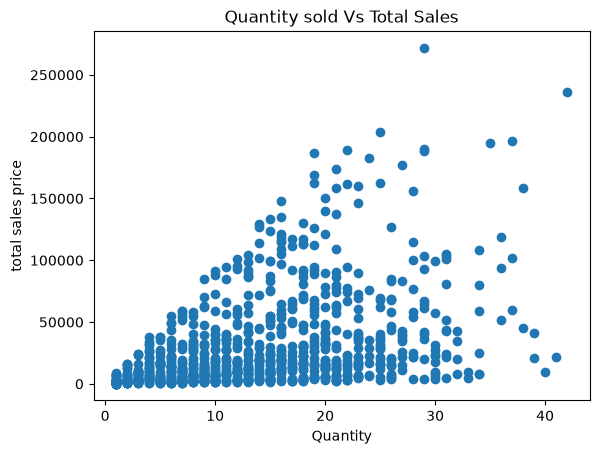

In [63]:
plt.scatter(df['Quantity_Sold'],df['Total_Sales'])
plt.xlabel('Quantity')
plt.ylabel('total sales price')
plt.title('Quantity sold Vs Total Sales')

Text(0.5, 1.0, 'Unit Price Vs Total Sales')

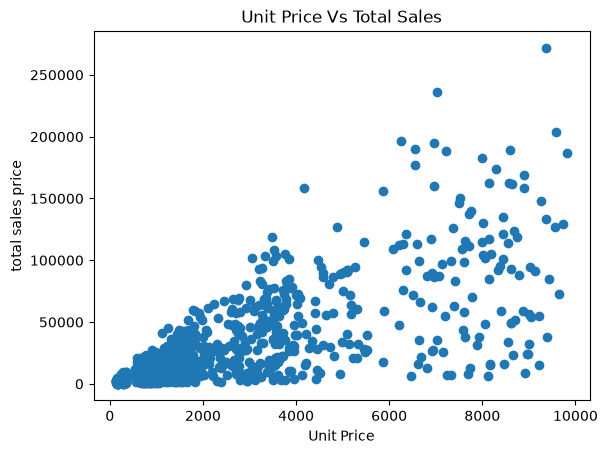

In [64]:
plt.scatter(df['Unit_Price'],df['Total_Sales'])
plt.xlabel('Unit Price')
plt.ylabel('total sales price')
plt.title('Unit Price Vs Total Sales')

Text(0.5, 1.0, 'Discount Vs Total Sales')

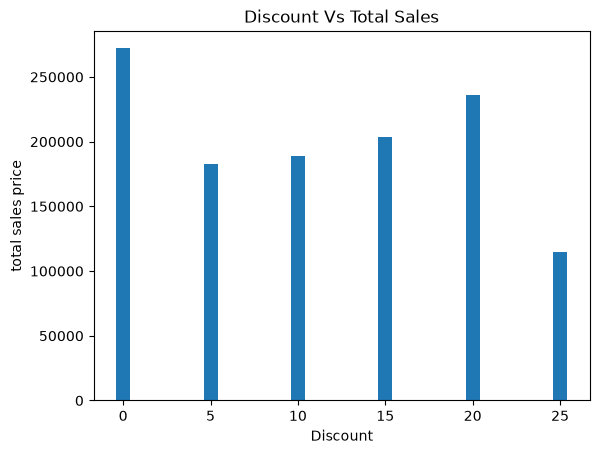

In [65]:
plt.bar(df['Discount'],df['Total_Sales'])
plt.xlabel('Discount')
plt.ylabel('total sales price')
plt.title('Discount Vs Total Sales')

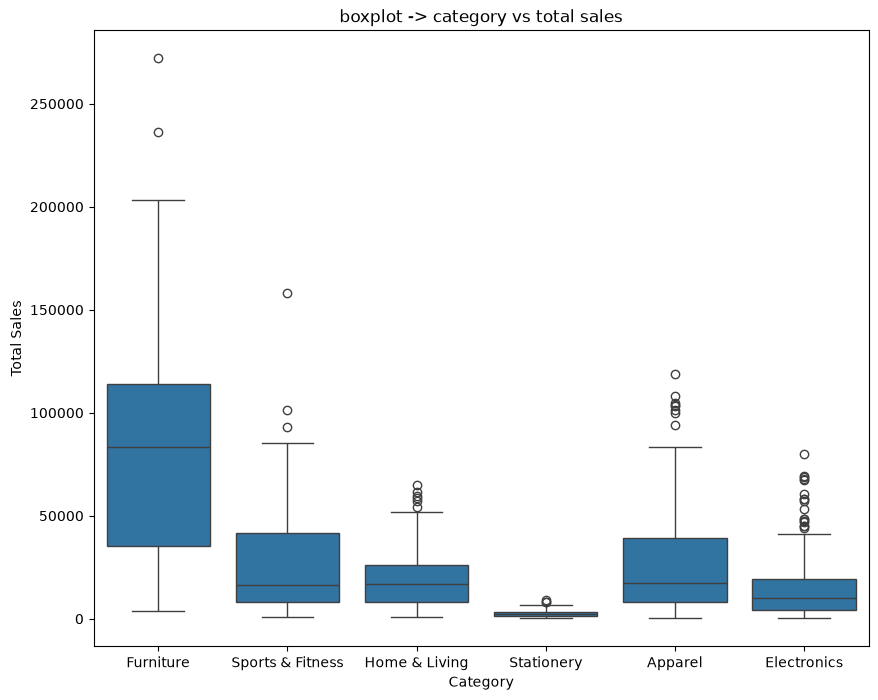

In [66]:
plt.figure(figsize=(10,8))
sns.boxplot(data= df, x='Category', y= 'Total_Sales')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.title('boxplot -> category vs total sales')
plt.show()

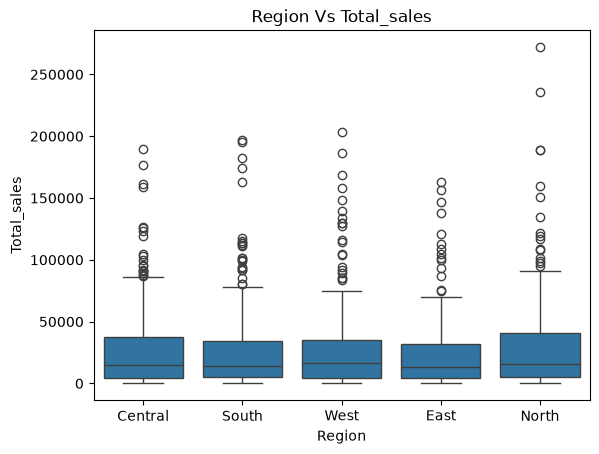

In [67]:
plt.Figure(figsize=(10,8))
sns.boxplot(data=df,x='Region', y='Total_Sales')
plt.xlabel('Region')
plt.ylabel('Total_sales')
plt.title("Region Vs Total_sales")
plt.show()

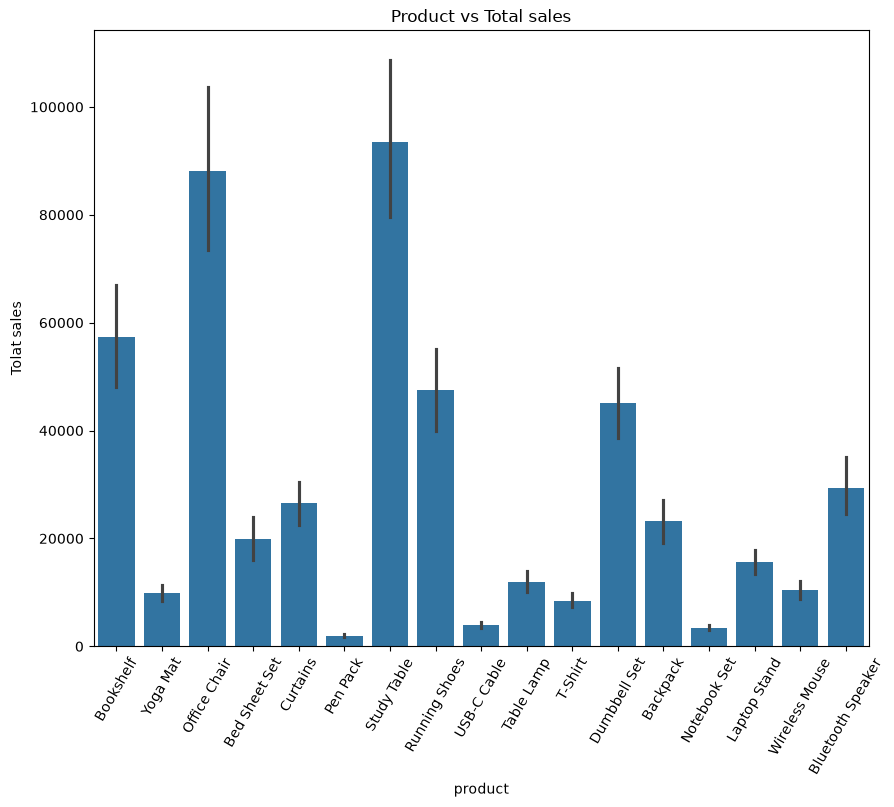

In [68]:
plt.figure(figsize=(10,8))
sns.barplot(data=df, x='Product', y='Total_Sales')
plt.xlabel("product")
plt.ylabel("Tolat sales")
plt.xticks(rotation = 60)
plt.title("Product vs Total sales")
plt.show()

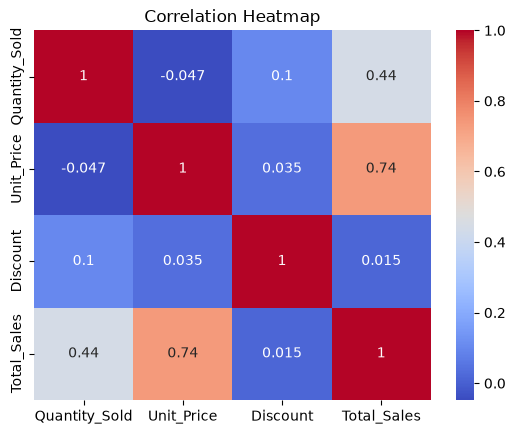

In [69]:
plt.Figure(figsize=(10,8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

## Feature Engineering

In [70]:
df['Date'] = pd.to_datetime(df['Date'])

In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           1000 non-null   datetime64[us]
 1   Product        1000 non-null   str           
 2   Category       1000 non-null   str           
 3   Region         1000 non-null   str           
 4   Quantity_Sold  1000 non-null   int64         
 5   Unit_Price     1000 non-null   float64       
 6   Discount       1000 non-null   float64       
 7   Total_Sales    1000 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(3)
memory usage: 88.8 KB


In [72]:
df['year'] = df['Date'].dt.year

In [73]:
df['Month'] = df['Date'].dt.month

In [74]:
df

,Date,Product,Category,Region,Quantity_Sold,Unit_Price,Discount,Total_Sales,year,Month
0,2024-01-01,Bookshelf,Furniture,Central,22,4533.15,5.0,94742.83,2024,1
1,2024-01-01,Yoga Mat,Sports & Fitness,South,10,745.02,5.0,7077.69,2024,1
2,2024-01-01,Office Chair,Furniture,West,4,7884.39,0.0,31537.56,2024,1
3,2024-01-02,Bed Sheet Set,Home & Living,West,2,1815.07,0.0,3630.14,2024,1
4,2024-01-02,Bed Sheet Set,Home & Living,West,18,1826.45,5.0,31232.29,2024,1
...,...,...,...,...,...,...,...,...,...,...
995,2025-12-29,Bookshelf,Furniture,Central,23,4588.59,15.0,89706.93,2025,12
996,2025-12-29,Notebook Set,Stationery,East,34,243.95,0.0,8294.30,2025,12
997,2025-12-30,Pen Pack,Stationery,West,12,165.17,0.0,1982.04,2025,12
998,2025-12-30,Backpack,Apparel,Central,17,1538.17,15.0,22226.56,2025,12


In [75]:
x = df[[
    'year',
    'Product',
    'Category',
    'Region',
    'Quantity_Sold',
    'Unit_Price',
    'Discount'
]]

In [76]:
x

,year,Product,Category,Region,Quantity_Sold,Unit_Price,Discount
0,2024,Bookshelf,Furniture,Central,22,4533.15,5.0
1,2024,Yoga Mat,Sports & Fitness,South,10,745.02,5.0
2,2024,Office Chair,Furniture,West,4,7884.39,0.0
3,2024,Bed Sheet Set,Home & Living,West,2,1815.07,0.0
4,2024,Bed Sheet Set,Home & Living,West,18,1826.45,5.0
...,...,...,...,...,...,...,...
995,2025,Bookshelf,Furniture,Central,23,4588.59,15.0
996,2025,Notebook Set,Stationery,East,34,243.95,0.0
997,2025,Pen Pack,Stationery,West,12,165.17,0.0
998,2025,Backpack,Apparel,Central,17,1538.17,15.0


In [77]:
y= df['Total_Sales']

In [78]:
y

0      94742.83
1       7077.69
2      31537.56
3       3630.14
4      31232.29
         ...   
995    89706.93
996     8294.30
997     1982.04
998    22226.56
999    38099.95
Name: Total_Sales, Length: 1000, dtype: float64

In [79]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=100)

In [80]:
x_train

,year,Product,Category,Region,Quantity_Sold,Unit_Price,Discount
675,2025,Notebook Set,Stationery,West,22,297.18,5.0
358,2024,Yoga Mat,Sports & Fitness,West,5,766.60,5.0
159,2024,Laptop Stand,Electronics,East,9,1093.22,5.0
533,2025,T-Shirt,Apparel,West,3,685.99,10.0
678,2025,Laptop Stand,Electronics,North,16,1328.70,5.0
...,...,...,...,...,...,...,...
855,2025,Dumbbell Set,Sports & Fitness,Central,11,3498.81,5.0
871,2025,Bluetooth Speaker,Electronics,East,7,2490.99,0.0
835,2025,Notebook Set,Stationery,West,23,302.89,5.0
792,2025,Backpack,Apparel,North,1,1657.51,0.0


In [81]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [82]:
cate_col = ['Product','Category','Region']

In [83]:
num_col = ['year','Quantity_Sold','Unit_Price','Discount']

In [84]:
tf= ColumnTransformer([
    ('tfoe',OneHotEncoder(sparse_output=False,handle_unknown='ignore'),cate_col),
    ('tfse',StandardScaler(),num_col)
],remainder='passthrough')

In [85]:
tf

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tfoe', ...), ('tfse', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

## Not Important
### To visualize the transformed x_train And Y_train data in perfect DataFrame not in 0 or 1

In [86]:
transformed_x_train = tf.fit_transform(x_train)
transformed_x_tr= pd.DataFrame(
    transformed_x_train,
    columns=tf.get_feature_names_out()
)

In [87]:
transformed_x_test = tf.transform(x_test)
transformed_x_ts= pd.DataFrame(
    transformed_x_test,
    columns=tf.get_feature_names_out()
)

In [88]:
transformed_x_tr

,tfoe__Product_Backpack,tfoe__Product_Bed Sheet Set,tfoe__Product_Bluetooth Speaker,tfoe__Product_Bookshelf,tfoe__Product_Curtains,tfoe__Product_Dumbbell Set,tfoe__Product_Laptop Stand,tfoe__Product_Notebook Set,tfoe__Product_Office Chair,tfoe__Product_Pen Pack,...,tfoe__Category_Stationery,tfoe__Region_Central,tfoe__Region_East,tfoe__Region_North,tfoe__Region_South,tfoe__Region_West,tfse__year,tfse__Quantity_Sold,tfse__Unit_Price,tfse__Discount
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.990050,0.981044,-0.860820,-0.258611
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,-1.010051,-1.013604,-0.665054,-0.258611
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,-1.010051,-0.544275,-0.528841,-0.258611
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.990050,-1.248268,-0.698671,0.472444
4,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.990050,0.277051,-0.430637,-0.258611
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.990050,-0.309610,0.474380,-0.258611
796,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.990050,-0.778939,0.054081,-0.989666
797,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.990050,1.098376,-0.858438,-0.258611
798,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.990050,-1.482933,-0.293511,-0.989666


In [89]:
transformed_x_ts

,tfoe__Product_Backpack,tfoe__Product_Bed Sheet Set,tfoe__Product_Bluetooth Speaker,tfoe__Product_Bookshelf,tfoe__Product_Curtains,tfoe__Product_Dumbbell Set,tfoe__Product_Laptop Stand,tfoe__Product_Notebook Set,tfoe__Product_Office Chair,tfoe__Product_Pen Pack,...,tfoe__Category_Stationery,tfoe__Region_Central,tfoe__Region_East,tfoe__Region_North,tfoe__Region_South,tfoe__Region_West,tfse__year,tfse__Quantity_Sold,tfse__Unit_Price,tfse__Discount
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,-1.010051,0.277051,2.534212,-0.989666
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,-1.010051,-0.426943,-0.276016,-0.989666
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.990050,0.863712,-0.927850,1.203500
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,-1.010051,0.277051,0.336182,1.934555
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.990050,-1.013604,-0.722822,-0.258611
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.990050,-1.482933,0.317570,-0.989666
196,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.990050,0.159718,-0.727422,-0.989666
197,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,-1.010051,0.511715,-0.662560,-0.258611
198,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,-1.010051,-1.130936,0.471569,-0.258611


In [90]:
from sklearn.linear_model import LinearRegression

In [91]:
pipe = Pipeline([
    ('preprocessing',tf),
    ('model', LinearRegression())
])

In [92]:
pipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['year','Product','Category',...,'Quantity_Sold','Unit_Price','Discount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tfoe', ...), ('tfse', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

In [93]:
y_pred = pipe.predict(x_test)

In [94]:
print(y_pred)

[ 1.00486843e+05  1.50992642e+04  1.50648330e+04  4.23102801e+04
 -1.06684713e+04 -1.45446071e+04  3.37205889e+04 -1.72940656e+03
  8.69663044e+04  2.14589054e+04  9.68257224e+04 -8.28917534e+03
 -1.22074695e+04  2.36150250e+04 -1.41149020e+04  6.74866505e+03
  1.39252125e+04  1.04003693e+05  7.96416816e+04 -1.32250933e+03
  2.54244328e+04 -1.05149333e+02  1.68205021e+04 -3.78656137e+02
  3.40356010e+04  5.08353114e+04  2.81623106e+04  1.26180196e+04
  2.53203759e+04 -2.15978140e+04  1.87654282e+04 -6.55309165e+03
  1.11205730e+05  4.73971504e+04  5.75788160e+04 -1.59825685e+04
 -2.70500681e+03  1.18694532e+04  4.98824536e+04  3.69203825e+04
  2.88814769e+04 -2.21068503e+04  5.70208744e+04 -7.88737637e+03
  1.36750329e+04  3.52002082e+04  1.85062962e+04  3.58962197e+04
  3.29380659e+04  1.14475307e+04  2.44852543e+04 -7.60364393e+03
  1.74441817e+03 -7.68840362e+03  1.47214945e+04  8.89526690e+04
  2.15241451e+04  2.86553979e+04  6.24946099e+04  3.83701465e+04
  1.08151498e+05  4.30991

In [95]:
print(y_test)

249    135008.16
353     16994.60
537      2435.63
424     40543.10
564      2983.38
         ...    
684      3122.80
644      9255.75
110     13211.12
28      13269.87
804    188894.20
Name: Total_Sales, Length: 200, dtype: float64


In [96]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score,root_mean_squared_error
import numpy as np

In [99]:
print('MAE',mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("RMSE",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2_score",r2_score(y_test,y_pred))

MAE 12187.656435604655
MSE 303307685.44208497
RMSE 17415.730976392722
R2_score 0.7952213595177087


In [98]:
import pickle

pickle.dump(pipe,open('Sales_Model.pkl','wb'))